<a href="https://colab.research.google.com/github/akshin-kuvshin/numerical-methods/blob/main/lab3/lab3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторная работа №3. Сплайн-функции

## Выполнил: Данила Аксёнов, гр. 932420

## Вариант: 1

## **Задания 5, 6, 7**

* По заданным значениям $ (x_i, y_i) $ построить линейный, параболический и кубический сплайны;
* На графике представить каждый сплайн и заданные значения. В конце на одном графике представить все три сплайна и заданные значения;
* Проанализировать полученные результаты и сделать выводы.

In [ ]:
import numpy as np
from matplotlib import pyplot as plt
print('Setup completed')

Setup completed


### Исходные данные:

In [ ]:
x = np.array([0.35, 0.48, 0.97, 1.08, 1.18, 1.35])
y = np.array([1.419, 1.616, 2.637, 2.944, 3.254, 4.119])
n = len(x) # == len(y)

In [ ]:
def plot_nodes(color='black'):
    for x_i, y_i in zip(x, y):
        plt.plot(x_i, y_i, 'x', color=color)

In [ ]:
h = np.array([x[i + 1] - x[i] for i in range(n - 1)])
h

array([0.13, 0.49, 0.11, 0.1 , 0.17])

## **Линейный сплайн:**

### Коэффициенты линейного сплайна:

In [ ]:
a = y[:-1]
a

array([1.419, 1.616, 2.637, 2.944, 3.254])

In [ ]:
b_linear = np.array([(y[i + 1] - y[i]) / h[i] for i in range(n - 1)])
b_linear

array([1.51538462, 2.08367347, 2.79090909, 3.1       , 5.08823529])

### График линейного сплайна:

In [ ]:
def f_linear(x_0):
    for i in range(n - 1):
        if x[i] <= x_0 <= x[i + 1]:
            h_0 = x_0 - x[i]
            y_0 = a[i] + b_linear[i] * h_0
            return y_0
    raise ValueError(f'x_0 must be between {x[0]} and {x[-1]}; got {x_0}')

In [ ]:
def plot_linear(m=100, color='#003f5c', label='linear'):
    x_ = np.linspace(x[0], x[-1], num=m)
    y_ = np.array(list(map(f_linear, x_)))
    plt.plot(x_, y_, '-', color=color, label=label)

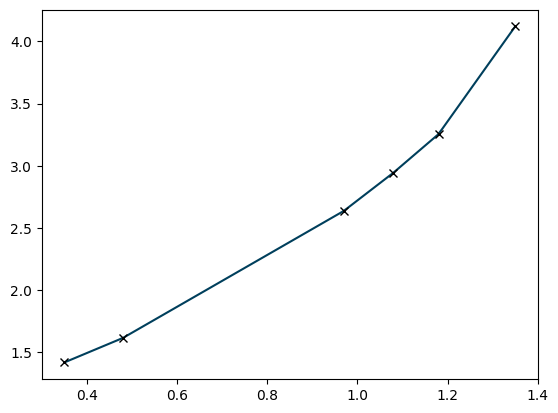

In [ ]:
plot_linear()
plot_nodes()
plt.show()

## **Параболический сплайн:**

### Коэффициенты параболического сплайна:

In [ ]:
g_parabolic = np.zeros(n - 1)
g_parabolic[-1] = (y[-2] - y[-1]) / h[-1]
for i in range(n - 2):
    g_parabolic[i] = (y[i + 2] - y[i + 1]) / h[i + 1] - (y[i + 1] - y[i]) / h[i]
g_parabolic

array([ 0.56828885,  0.70723562,  0.30909091,  1.98823529, -5.08823529])

In [ ]:
c_parabolic = np.zeros(n - 1)
c_parabolic[-1] = g_parabolic[-1] / h[-1]
for i in range(n - 3, 0 - 1, -1):
    c_parabolic[i] = (g_parabolic[i] - c_parabolic[i + 1] * h[i + 1]) / h[i]
c_parabolic

array([-53.12558805,  15.25431694, -61.52163345,  70.76470588,
       -29.93079585])

In [ ]:
b_parabolic = np.array([(y[i + 1] - y[i]) / h[i] - c_parabolic[i] * h[i] for i in range(n - 1)])
b_parabolic

array([ 8.42171106, -5.39094183,  9.55828877, -3.97647059, 10.17647059])

### График параболического сплайна:

In [ ]:
def f_parabolic(x_0):
    for i in range(n - 1):
        if x[i] <= x_0 <= x[i + 1]:
            h_0 = x_0 - x[i]
            y_0 = a[i] + b_parabolic[i] * h_0 + c_parabolic[i] * h_0 ** 2
            return y_0
    raise ValueError(f'x_0 must be between {x[0]} and {x[-1]}; got {x_0}')

In [ ]:
def plot_parabolic(m=100, color='#ff6361', label='parabolic'):
    x_ = np.linspace(x[0], x[-1], num=m)
    y_ = np.array(list(map(f_parabolic, x_)))
    plt.plot(x_, y_, '-', color=color, label=label)

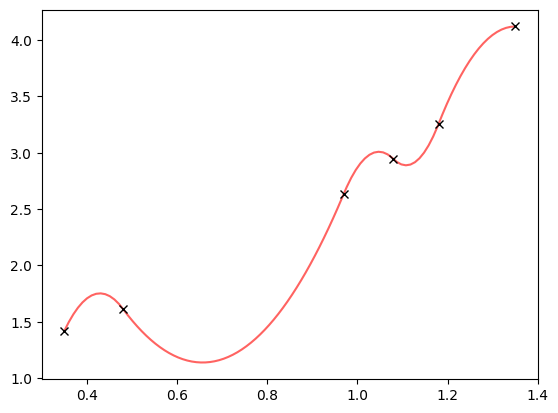

In [ ]:
plot_parabolic()
plot_nodes()
plt.show()

## **Кубический сплайн:**

### Коэффициенты кубического сплайна:

In [ ]:
g_cubic = np.zeros(n - 1)
for i in range(1, n - 1):
    g_cubic[i] = 3 * ((y[i + 1] - y[i]) / h[i] - (y[i] - y[i - 1]) / h[i - 1])
g_cubic

array([0.        , 1.70486656, 2.12170686, 0.92727273, 5.96470588])

In [ ]:
xi = np.zeros(n - 1)
for i in range(1, n - 1):
    xi[i] = -h[i] / (h[i - 1] * xi[i - 1] + 2 * (h[i - 1] + h[i]))
xi

array([ 0.        , -0.39516129, -0.10930363, -0.2451121 , -0.32978409])

In [ ]:
eta = np.zeros(n - 1)
for i in range(1, n - 1):
    eta[i] = (g_cubic[i] - h[i - 1] * eta[i - 1]) / (h[i - 1] * xi[i - 1] + 2 * (h[i - 1] + h[i]))
eta

array([ 0.        ,  1.37489239,  1.43884277,  1.88491208, 11.20531578])

In [ ]:
c_cubic = np.zeros(n)
c_cubic[-1] = 0
for i in range(n - 2, 0 - 1, -1):
    c_cubic[i] = xi[i] * c_cubic[i + 1] + eta[i]
c_cubic

array([ 0.        ,  0.76910071,  1.53302385, -0.86164637, 11.20531578,
        0.        ])

In [ ]:
b_cubic = np.array([(y[i + 1] - y[i]) / h[i] - h[i] * (c_cubic[i + 1] + 2 * c_cubic[i]) / 3 for i in range(n - 1)])
b_cubic

array([1.48205692, 1.58204001, 2.71008104, 2.78393257, 3.81829951])

In [ ]:
d = np.array([(c_cubic[i + 1] - c_cubic[i]) / (3 * h[i]) for i in range(n - 1)])
d

array([  1.97205309,   0.51967561,  -7.25657641,  40.22320714,
       -21.9712074 ])

### График кубического сплайна:

In [ ]:
def f_cubic(x_0):
    for i in range(n - 1):
        if x[i] <= x_0 <= x[i + 1]:
            h_0 = x_0 - x[i]
            y_0 = a[i] + b_cubic[i] * h_0 + c_cubic[i] * h_0 ** 2 + d[i] * h_0 ** 3
            return y_0
    raise ValueError(f'x_0 must be between {x[0]} and {x[-1]}; got {x_0}')

In [ ]:
def plot_cubic(m=100, color='#ffa600', label='cubic'):
    x_ = np.linspace(x[0], x[-1], num=m)
    y_ = np.array(list(map(f_cubic, x_)))
    plt.plot(x_, y_, '-', color=color, label=label)

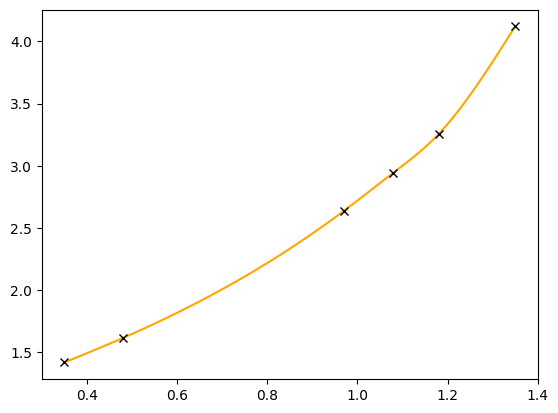

In [ ]:
plot_cubic()
plot_nodes()
plt.show()

## **Общий график всех трёх сплайнов:**

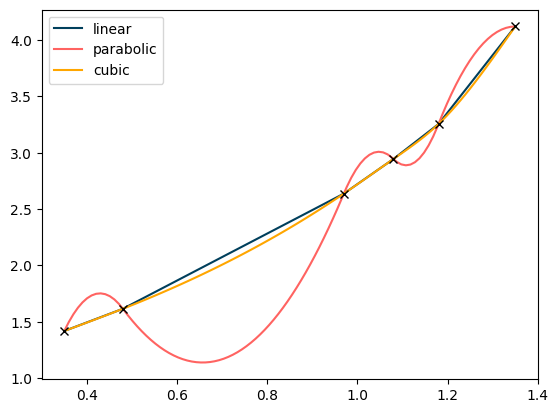

In [ ]:
plot_linear()
plot_parabolic()
plot_cubic()
plot_nodes()
plt.legend()
plt.show()

## **Вывод:**

Кубический сплайн оказался похожим на линейный, и это не ошибка (я перепроверил его путём сравнения со встроенным `scipy.interpolate.CubicSpline`), а особенность природы исходных данных (узлов), которые образуют совсем немного выпуклую кривую, очень похожую на прямую.

В этом смысле параболический сплайн вызывает у меня сомнения, т.к. добавляет множество перегибов и, соответственно, локальных минимумов/максимумов (по одному между каждой парой соседних узлов), поэтому я уверен, что он избыточен и вносит в данные лишнюю информацию.

Наиболее подходящим для имеющихся исходных данных (по крайней мере, насколько это можно судить по 6-и точкам) я считаю кубический сплайн в силу того, что он не имеет недостатков линейного ("угловатость" в узлах и большая ошибка в точках, расстояние от которых до ближайшего узла велико) и не вносит "отсебятину", которую вносит параболический, тем самым основываясь лишь на исходных данных и максимально им соответствуя. К тому же, кубический сплайн гарантирует непрерывность второй производной, что является ещё одним его преимуществом.